# Reproducing a Variance-Aware Bandit Experiment

**Research paper:** *A Framework for Fair Evaluation of Variance-Aware Bandit Algorithms*

This notebook runs a transparent, reproducible **illustrative reproduction** of Scenario C:
- Arm 1 reward probability: 0.890
- Arm 2 reward probability: 0.895 (optimal arm)
- Horizon: 1,000,000 decisions per trial (configurable below)
- Algorithms: standard UCB1 and a common UCB-Tuned variant

**Important:** Implementations and defaults can differ from the paper's code. Before calling
this an exact reproduction, compare the formulas, initialization, tie-breaking, parameter
settings, and random-number handling below with the authors' repository. The paper's results
are shown only as reference values; this notebook never forces its outputs to match them.

## 1. Configuration

Start with a shorter run to verify that everything works. Then set `HORIZON = 1_000_000`
and `N_TRIALS = 100` for a more expensive experiment. The full run may take several minutes
depending on your computer.

In [1]:
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

P_ARMS = np.array([0.890, 0.895], dtype=float)
OPTIMAL_MEAN = float(P_ARMS.max())
HORIZON = 100_000       # Change to 1_000_000 for the paper-scale horizon
N_TRIALS = 10           # Change to 100 for the paper-scale trial count
BASE_SEED = 20261011
EPS = 1e-12

print("Scenario C")
print(f"Arm probabilities: {P_ARMS.tolist()}")
print(f"Optimal expected reward: {OPTIMAL_MEAN:.3f}")
print(f"Reward gap: {np.max(P_ARMS) - np.min(P_ARMS):.3f}")
print(f"Horizon per trial: {HORIZON:,}")
print(f"Independent trials: {N_TRIALS}")

Scenario C
Arm probabilities: [0.89, 0.895]
Optimal expected reward: 0.895
Reward gap: 0.005
Horizon per trial: 100,000
Independent trials: 10


## 2. Algorithm definitions

**UCB1** selects the arm with the highest empirical mean plus an exploration bonus:

\[
\widehat{\mu}_i + \sqrt{\frac{2\ln(t)}{N_i}}
\]

**UCB-Tuned** uses a variance-sensitive exploration bonus. This notebook implements a
commonly used UCB-Tuned form for rewards in [0, 1]:

\[
\widehat{\mu}_i + \sqrt{\frac{\ln(t)}{N_i}
\min\left(\frac14,\widehat{V}_i+
\sqrt{\frac{2\ln(t)}{N_i}}\right)}
\]

Here, \(\widehat{V}_i\) is the empirical variance. Confirm this exact variant against the
paper/repository before claiming exact reproduction. Both algorithms first pull each arm once.

In [2]:
def choose_ucb1(counts, means, t, rng):
    """Choose an arm using UCB1; untried arms are selected first."""
    untried = np.flatnonzero(counts == 0)
    if len(untried):
        return int(untried[0])
    bonus = np.sqrt(2.0 * np.log(t) / counts)
    scores = means + bonus
    # Random tie-breaking avoids a systematic preference for arm index 0.
    best = np.flatnonzero(np.isclose(scores, scores.max(), rtol=0, atol=EPS))
    return int(rng.choice(best))


def choose_ucb_tuned(counts, means, variances, t, rng):
    """Choose an arm using a common variance-aware UCB-Tuned formula."""
    untried = np.flatnonzero(counts == 0)
    if len(untried):
        return int(untried[0])
    log_t = np.log(t)
    variance_term = variances + np.sqrt(2.0 * log_t / counts)
    bonus = np.sqrt((log_t / counts) * np.minimum(0.25, variance_term))
    scores = means + bonus
    best = np.flatnonzero(np.isclose(scores, scores.max(), rtol=0, atol=EPS))
    return int(rng.choice(best))

## 3. Run one trial

Rewards are sampled as Bernoulli random variables: reward 1 with probability \(p_i\), else 0.
The code records cumulative pseudo-regret:

\[
R_T = \sum_{t=1}^{T}(\mu^* - \mu_{A_t})
\]

For this fixed two-arm environment, each selection of the suboptimal arm adds exactly
\(0.895 - 0.890 = 0.005\) pseudo-regret.

In [3]:
def run_trial(algorithm, probabilities, horizon, seed, keep_curve=True):
    rng = np.random.default_rng(seed)
    k = len(probabilities)

    counts = np.zeros(k, dtype=np.int64)
    reward_sums = np.zeros(k, dtype=float)
    reward_square_sums = np.zeros(k, dtype=float)
    means = np.zeros(k, dtype=float)
    variances = np.zeros(k, dtype=float)

    cumulative_pseudo_regret = 0.0
    cumulative_regret_curve = np.empty(horizon, dtype=float) if keep_curve else None
    suboptimal_pulls = 0
    observed_reward_sum = 0.0
    optimal_mean = float(np.max(probabilities))

    for step in range(1, horizon + 1):
        if algorithm == "UCB1":
            arm = choose_ucb1(counts, means, step, rng)
        elif algorithm == "UCB-Tuned":
            arm = choose_ucb_tuned(counts, means, variances, step, rng)
        else:
            raise ValueError(f"Unknown algorithm: {algorithm}")

        reward = float(rng.random() < probabilities[arm])
        counts[arm] += 1
        reward_sums[arm] += reward
        reward_square_sums[arm] += reward * reward
        means[arm] = reward_sums[arm] / counts[arm]

        # Population-style empirical variance, clamped against floating-point negatives.
        variances[arm] = max(
            0.0, reward_square_sums[arm] / counts[arm] - means[arm] ** 2
        )

        cumulative_pseudo_regret += optimal_mean - probabilities[arm]
        suboptimal_pulls += int(probabilities[arm] < optimal_mean)
        observed_reward_sum += reward

        if keep_curve:
            cumulative_regret_curve[step - 1] = cumulative_pseudo_regret

    result = {
        "algorithm": algorithm,
        "pseudo_regret": cumulative_pseudo_regret,
        "suboptimal_pulls": suboptimal_pulls,
        "suboptimal_action_ratio": suboptimal_pulls / horizon,
        "observed_average_reward": observed_reward_sum / horizon,
        "arm_1_pulls": int(counts[0]),
        "arm_2_pulls": int(counts[1]),
    }
    if keep_curve:
        result["regret_curve"] = cumulative_regret_curve
    return result

## 4. Quick smoke test

Run a short trial first. This checks that the code executes and the outputs are sensible.

In [4]:
smoke = run_trial("UCB-Tuned", P_ARMS, horizon=2_000, seed=BASE_SEED, keep_curve=True)
print({k: v for k, v in smoke.items() if k != "regret_curve"})
assert smoke["arm_1_pulls"] + smoke["arm_2_pulls"] == 2_000
assert 0 <= smoke["suboptimal_action_ratio"] <= 1
print("Smoke test passed.")

{'algorithm': 'UCB-Tuned', 'pseudo_regret': np.float64(6.034999999999894), 'suboptimal_pulls': 1207, 'suboptimal_action_ratio': 0.6035, 'observed_average_reward': 0.889, 'arm_1_pulls': 1207, 'arm_2_pulls': 793}
Smoke test passed.


## 5. Run repeated trials

Each algorithm/trial receives a deterministic seed. For a fair comparison, both algorithms
use the same list of trial seeds, although their internal random-number consumption may differ.
Averages and standard deviations are computed from the results actually generated here.

In [5]:
algorithms = ["UCB1", "UCB-Tuned"]
all_rows = []
curves = {name: [] for name in algorithms}
start = time.perf_counter()

for trial in range(N_TRIALS):
    trial_seed = BASE_SEED + trial
    for algorithm in algorithms:
        result = run_trial(
            algorithm, P_ARMS, HORIZON, seed=trial_seed, keep_curve=True
        )
        curves[algorithm].append(result.pop("regret_curve"))
        result["trial"] = trial + 1
        result["seed"] = trial_seed
        all_rows.append(result)

elapsed = time.perf_counter() - start
trial_df = pd.DataFrame(all_rows)

print(f"Completed {len(trial_df)} runs in {elapsed:.1f} seconds.")
display(trial_df.head())

Completed 20 runs in 128.5 seconds.


,algorithm,pseudo_regret,suboptimal_pulls,suboptimal_action_ratio,observed_average_reward,arm_1_pulls,arm_2_pulls,trial,seed
0,UCB1,191.225,38245,0.38245,0.89274,38245,61755,1,20261011
1,UCB-Tuned,191.990,38398,0.38398,0.89263,38398,61602,1,20261011
2,UCB1,178.035,35607,0.35607,0.89323,35607,64393,2,20261012
3,UCB-Tuned,153.650,30730,0.30730,0.89349,30730,69270,2,20261012
4,UCB1,216.990,43398,0.43398,0.89243,43398,56602,3,20261013


## 6. Summary results

The reported pseudo-regret is based on known arm means, not on noisy realized reward totals.
The standard deviation below is across independent trials.

In [6]:
summary = (
    trial_df.groupby("algorithm")
    .agg(
        mean_pseudo_regret=("pseudo_regret", "mean"),
        std_pseudo_regret=("pseudo_regret", "std"),
        mean_suboptimal_action_ratio=("suboptimal_action_ratio", "mean"),
        std_suboptimal_action_ratio=("suboptimal_action_ratio", "std"),
        mean_observed_reward=("observed_average_reward", "mean"),
        mean_arm_1_pulls=("arm_1_pulls", "mean"),
        mean_arm_2_pulls=("arm_2_pulls", "mean"),
    )
    .reset_index()
)

display(summary.round(6))

# Save actual outputs so they can be included as assignment evidence.
trial_df.to_csv("scenario_c_trial_results.csv", index=False)
summary.to_csv("scenario_c_summary_results.csv", index=False)
print("Saved scenario_c_trial_results.csv and scenario_c_summary_results.csv")

,algorithm,mean_pseudo_regret,std_pseudo_regret,mean_suboptimal_action_ratio,std_suboptimal_action_ratio,mean_observed_reward,mean_arm_1_pulls,mean_arm_2_pulls
0,UCB-Tuned,114.6360,56.719911,0.229272,0.113440,0.893914,22927.2,77072.8
1,UCB1,185.5475,21.669036,0.371095,0.043338,0.893245,37109.5,62890.5


Saved scenario_c_trial_results.csv and scenario_c_summary_results.csv


## 7. Plot mean cumulative pseudo-regret

The shaded region shows ±1 standard deviation across trials. This is descriptive variability,
not a confidence interval.

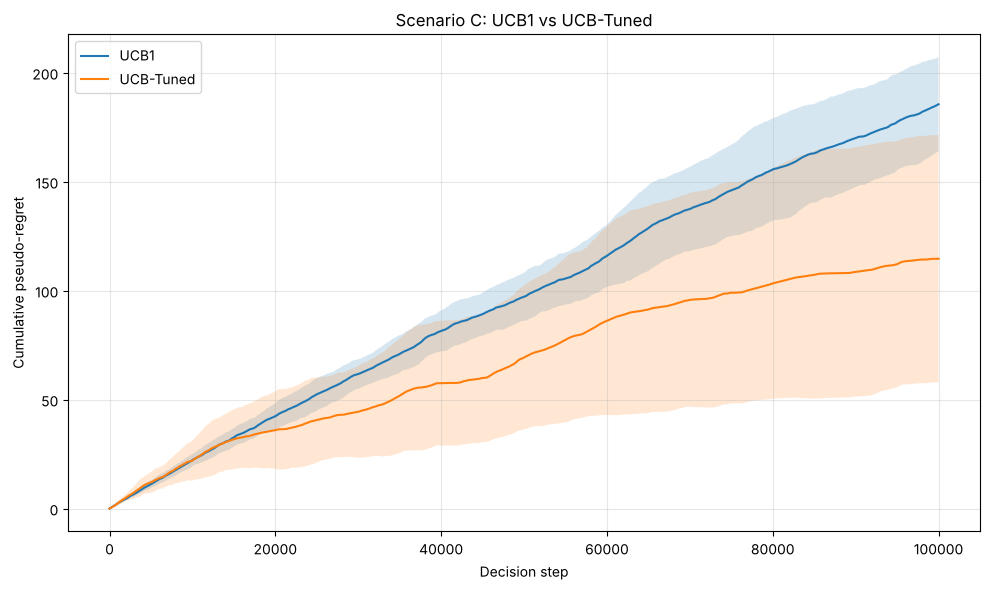

In [7]:
plt.figure(figsize=(10, 6))
time_points = np.arange(1, HORIZON + 1)

for algorithm in algorithms:
    matrix = np.vstack(curves[algorithm])
    mean_curve = matrix.mean(axis=0)
    std_curve = matrix.std(axis=0, ddof=1) if N_TRIALS > 1 else np.zeros(HORIZON)
    plt.plot(time_points, mean_curve, label=algorithm)
    plt.fill_between(
        time_points,
        np.maximum(0, mean_curve - std_curve),
        mean_curve + std_curve,
        alpha=0.18,
    )

plt.xlabel("Decision step")
plt.ylabel("Cumulative pseudo-regret")
plt.title("Scenario C: UCB1 vs UCB-Tuned")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Mathematical consistency check

In Scenario C, the suboptimal arm's expected reward is 0.890 and the optimal arm's expected
reward is 0.895. Therefore:

\[
R_T = 0.005 \times N_{\text{suboptimal}}
\]

This should match the pseudo-regret recorded by the simulator, up to floating-point rounding.

In [8]:
gap = float(np.max(P_ARMS) - np.min(P_ARMS))
trial_df["regret_from_suboptimal_pulls"] = gap * trial_df["suboptimal_pulls"]
trial_df["absolute_check_error"] = np.abs(
    trial_df["pseudo_regret"] - trial_df["regret_from_suboptimal_pulls"]
)

display(
    trial_df[
        ["algorithm", "trial", "pseudo_regret",
         "regret_from_suboptimal_pulls", "absolute_check_error"]
    ].head(10).round(10)
)
assert trial_df["absolute_check_error"].max() < 1e-8
print("Consistency check passed: regret = gap × number of suboptimal pulls.")

,algorithm,trial,pseudo_regret,regret_from_suboptimal_pulls,absolute_check_error
0,UCB1,1,191.225,191.225,1.000000e-10
1,UCB-Tuned,1,191.990,191.990,1.000000e-10
2,UCB1,2,178.035,178.035,1.000000e-10
3,UCB-Tuned,2,153.650,153.650,1.000000e-10
4,UCB1,3,216.990,216.990,1.000000e-10
5,UCB-Tuned,3,145.345,145.345,1.000000e-10
6,UCB1,4,187.050,187.050,1.000000e-10
7,UCB-Tuned,4,111.145,111.145,0.000000e+00
8,UCB1,5,214.155,214.155,1.000000e-10
9,UCB-Tuned,5,59.785,59.785,0.000000e+00


Consistency check passed: regret = gap × number of suboptimal pulls.


## 9. Compare with the paper (reference only)

The values below are the reported Scenario C reference values discussed in the assignment
analysis. They are **not** the results of this notebook and are not used to modify the output.
Only compare them directly if the paper uses the same algorithm implementation, initialization,
tie-breaking, hyperparameters, seeds, horizon, and averaging procedure.

Reference values:
- UCB: regret 1172.57; suboptimal-action ratio 0.23451
- UCB-Tuned: regret 226.09; suboptimal-action ratio 0.04522

If your results differ, report the difference and investigate implementation/configuration
differences. Do not overwrite your measured results with the paper's numbers.

In [9]:
paper_reference = pd.DataFrame([
    {"algorithm": "UCB (paper label)", "paper_mean_regret": 1172.57,
     "paper_suboptimal_action_ratio": 0.23451},
    {"algorithm": "UCB-Tuned", "paper_mean_regret": 226.09,
     "paper_suboptimal_action_ratio": 0.04522},
])
display(paper_reference)

,algorithm,paper_mean_regret,paper_suboptimal_action_ratio
0,UCB (paper label),1172.57,0.23451
1,UCB-Tuned,226.09,0.04522


## 10. Suggested conclusion template

Fill in the blanks from your generated `summary` table after running the notebook:

> In Scenario C, with Bernoulli reward probabilities 0.890 and 0.895, the observed mean
> pseudo-regret was **[your UCB value]** for UCB1 and **[your UCB-Tuned value]** for UCB-Tuned
> over **[your horizon]** steps and **[your trial count]** trials. The regret consistency check
> passed because pseudo-regret equals the reward gap (0.005) multiplied by the number of
> suboptimal-arm selections. These results are a reproduction using the implementation shown
> here; exact agreement with the paper requires matching the authors' implementation and settings.

## Evidence to include in your assignment
1. Screenshot of the configuration cell and successful smoke test.
2. Screenshot of the result summary table.
3. Screenshot of the cumulative-regret chart.
4. Include or retain the two CSV files and notebook as supporting evidence, if your submission
   platform permits supplementary artifacts.